# 04 — Scénarios de référence (S5-C01, S5-C03)

Réponses attendues des quatre scénarios du plan (§4.8), calculées avec le modèle Python (niveau 2, PID retenu, soupape à hystérésis). Le moteur TypeScript, testé dans `scenarios.test.ts`, doit donner les mêmes ordres de grandeur.

| # | Scénario | Événement |
| --- | --- | --- |
| 1 | Démarrage à froid | $C_A=0$, $T=300$ K, PID auto, $T_{sp}=350$ K |
| 2 | Panne de pompe | $\eta_{pompe}\to0$ à $t=20$ s |
| 3 | Encrassement | $f$ : 1 → 0,4 en 120 s à partir de $t=10$ s |
| 4 | Quench d'urgence | scénario 2 avancé à $T=390$ K, puis quench (diluant 60 L à 280 K, inhibiteur ×0,05 pendant 180 s, alimentation coupée) |

In [1]:
import sys, json
sys.path.insert(0, ".")
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
from scipy.integrate import solve_ivp

from cstr_model import (Params, Inputs, rhs, arrhenius, UA_eff, steady_states_level1,
                        jacobian_level1, R_GAS, p_sat_water, relief_heat)
from presets_py import seborg, propylene_oxide
from pid_sim import (Pid, closed_loop, linearize, steady_state_level2, closed_loop_spectral_abscissa,
                     search_gains, max_recoverable_perturbation, step_metrics)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
GOLDEN = Path("..") / "tests" / "golden"


In [2]:
p = seborg().with_(level=2, relief=True)
SS = [0.5, 350.0, 300.0, 0.3]
mk_pid = lambda: Pid(0.4, 0.01, 3.0, 2.0, 0.3, 350.0)

def crossings(t, T, thresholds):
    out = {}
    for name, th in thresholds.items():
        i = np.where(T >= th)[0]
        out[name] = round(float(t[i[0]]), 1) if len(i) else None
    return out

# --- Scénario 1 ---
t1, X1, V1 = closed_loop(p, [0.0, 300.0, 300.0, 0.0], mk_pid(), t_end=700)
# --- Scénario 2 ---
t2, X2, V2 = closed_loop(p, SS, mk_pid(), t_end=400, events=[(20, {"pump_eff": 0.0})], T_abort=450)
# --- Scénario 3 ---
def fouling_events():
    return [(10 + s, {"fouling": 1 - 0.6 * min(s, 120) / 120}) for s in np.arange(0, 121, 1.0)]
t3, X3, V3 = closed_loop(p, SS, mk_pid(), t_end=300, events=fouling_events())
# --- Scénario 4 ---
ta, Xa, _ = closed_loop(p, SS, mk_pid(), t_end=400, events=[(5, {"pump_eff": 0.0})], stop_on_T=390.0)
x_ready = Xa[:, -1]; t_ready = ta[-1]
pid4 = mk_pid()
t4, X4, V4 = closed_loop(p, list(x_ready), pid4, t_end=400, events=[(0, {"pump_eff": 0.0, "quench": True})], T_abort=450)

t4b, X4b, _ = closed_loop(p, list(x_ready), mk_pid(), t_end=400,
                          events=[(0, {"pump_eff": 0.0, "quench": "keep_feed"})], T_abort=450)
thr = {"H (365 K)": 365, "HH (380 K)": 380, "rupture (450 K)": 450}
pd.DataFrame({
    "1 démarrage": {"T finale [K]": round(X1[1][-1], 2), "T max [K]": round(X1[1].max(), 2)},
    "2 panne pompe": {**crossings(t2, X2[1], thr), "T max [K]": round(X2[1].max(), 1)},
    "3 encrassement": {"vanne saturée dès t [s]": round(float(t3[np.argmax(V3 > 0.98)]), 1), "T finale [K]": round(X3[1][-1], 1)},
    "4 quench (+ arrêt alim.)": {"T avant quench [K]": round(x_ready[1], 1), "T min [K]": round(X4[1].min(), 1),
                 "T finale [K]": round(X4[1][-1], 1), "rupture": bool(X4[1].max() >= 450)},
    "4 bis quench SANS arrêt alim.": {"T min [K]": round(X4b[1].min(), 1), "T finale [K]": round(X4b[1][-1], 1),
                 "rupture": bool(X4b[1].max() >= 450), "T max [K]": round(X4b[1].max(), 1)},
})

,1 démarrage,2 panne pompe,3 encrassement,4 quench (+ arrêt alim.),4 bis quench SANS arrêt alim.
T finale [K],350.0,NaN,413.9,356.1,450.0
T max [K],350.0,450.0,NaN,NaN,450.0
H (365 K),NaN,56.6,NaN,NaN,NaN
HH (380 K),NaN,68.6,NaN,NaN,NaN
rupture (450 K),NaN,229.8,NaN,NaN,NaN
vanne saturée dès t [s],NaN,NaN,61.4,NaN,NaN
T avant quench [K],NaN,NaN,NaN,390.1,NaN
T min [K],NaN,NaN,NaN,348.9,348.9
rupture,NaN,NaN,NaN,False,True


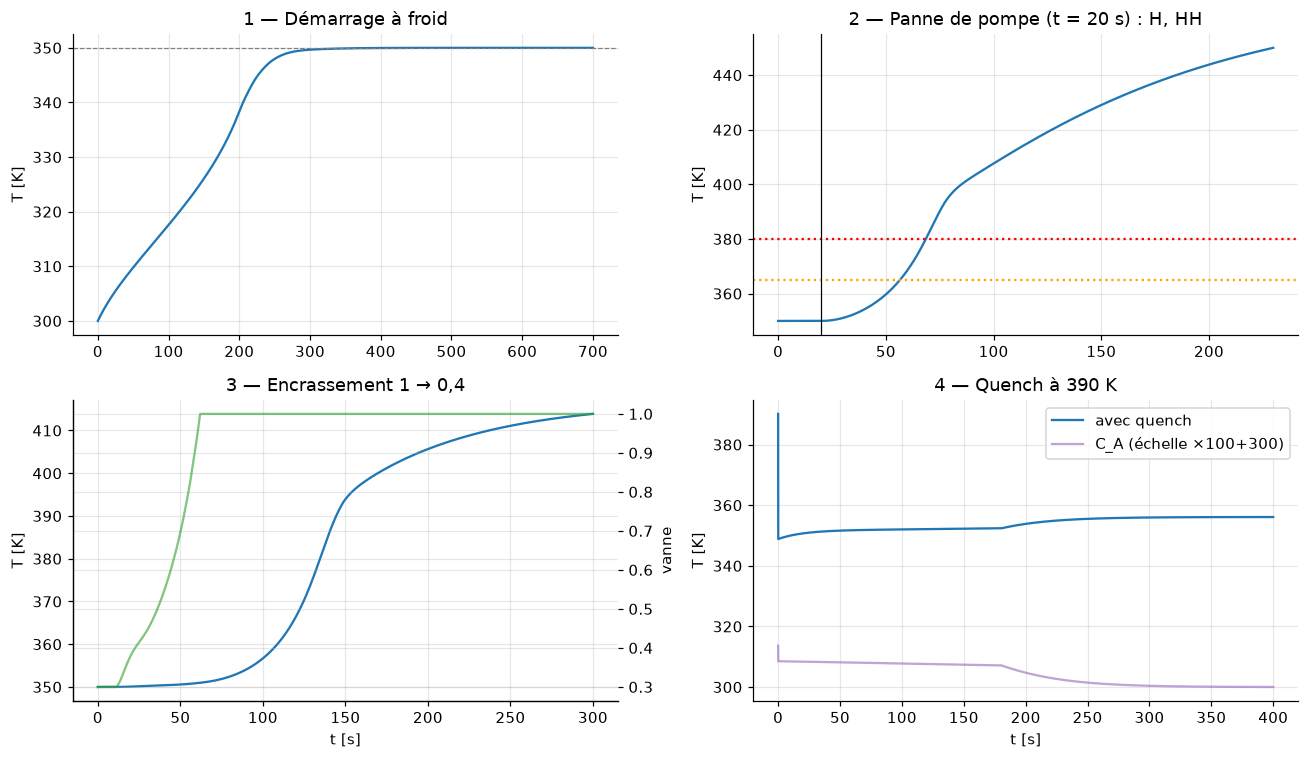

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
axes[0, 0].plot(t1, X1[1]); axes[0, 0].axhline(350, color="gray", ls="--", lw=0.8)
axes[0, 0].set(title="1 — Démarrage à froid", ylabel="T [K]")
axes[0, 1].plot(t2, X2[1], label="T"); axes[0, 1].axhline(365, color="orange", ls=":"); axes[0, 1].axhline(380, color="red", ls=":")
axes[0, 1].axvline(20, color="k", lw=0.8); axes[0, 1].set(title="2 — Panne de pompe (t = 20 s) : H, HH", ylabel="T [K]")
axes[1, 0].plot(t3, X3[1], label="T"); ax2 = axes[1, 0].twinx(); ax2.plot(t3, V3, color="tab:green", alpha=.6); ax2.set_ylabel("vanne")
axes[1, 0].set(title="3 — Encrassement 1 → 0,4", ylabel="T [K]", xlabel="t [s]")
axes[1, 1].plot(t4, X4[1], label="avec quench"); axes[1, 1].plot(t4, X4[0] * 100 + 300, color="tab:purple", alpha=.6, label="C_A (échelle ×100+300)")
axes[1, 1].set(title="4 — Quench à 390 K", xlabel="t [s]", ylabel="T [K]"); axes[1, 1].legend()
fig.tight_layout()

## Recette (S5-C03) — réalisme et enseignements

* **Scénario 1.** Montée régulière sans dépassement notable ni alarme : le démarrage à froid est maîtrisé par le PID.
* **Scénario 2.** L'alarme **H** (365 K) apparaît ≈ 37 s après la panne, **HH** (380 K) ≈ 12 s plus tard, la soupape s'ouvre peu après (P ≥ 3 bar, T ≈ 393 K). La soupape, **volontairement sous-dimensionnée** (Ø ≈ 2,8 mm), ne suffit pas : sans intervention la température monte lentement jusqu'à la rupture. La fenêtre d'intervention entre HH et la rupture est d'environ 160 s simulées, soit ≈ 16 s à ×10.
* **Scénario 3.** La vanne sature dès $t\approx61$ s (encrassement ≈ 0,7) ; la température dérive ensuite vers un état chaud (≈ 414 K à $t=300$ s, encore en hausse lente) : perte de contrôle progressive, sans pic brutal. Une action opérateur (réduire $F$ ou $C_{A,in}$) la prévient.
* **Scénario 4.** Le quench dilue $A$, refroidit le milieu et coupe l'alimentation : la réaction s'éteint. **Le quench sans coupure de l'alimentation ne suffit pas** (ligne « 4 bis » du tableau) : la vanne d'alimentation continue d'apporter du réactif à 350 K alors que l'enveloppe est hors service.

## Limites du modèle (à signaler aux utilisateurs)

* Pression = inerte + vapeur saturante de **l'eau** : le milieu réel contient du réactif et des produits.
* Chaleur latente constante (2,257 MJ/kg) ; débit de soupape en écoulement compressible simplifié ; pas de perte de masse liquide à la soupape.
* Volume constant (surverse), réaction d'ordre 1 irréversible, paroi de cuve en équilibre thermique instantané avec le milieu.